# Kedi mi Köpek mi? PyTorch ile Görüntü Sınıflandırma

~25.000 kedi/köpek fotoğrafıyla ikili sınıflandırıcı: veri temizliğinden transfer learning'e kadar derin öğrenmenin temel adımları.

**Bölümler:** 0 Kurulum · 1 Veri temizliği · 2 Bölme · 3 EDA · 4 Veri pipeline'ı · 5 Sıfırdan CNN · 6 Augmentation + Dropout · 7 Transfer learning · 8 Değerlendirme · 9 Tahmin ve kaydetme · 10 Sonuç

**Colab:** `Çalışma zamanı → Çalışma zamanı türünü değiştir → GPU` seçip `Tümünü çalıştır`. Veri yoksa `kagglehub` ile indirilir. Tüm veriyle çalışmak için `SUBSET_SIZE = None` yapın.

## 0. Kurulum

Kütüphaneleri yüklüyor, seed'leri sabitliyor ve cihazı seçiyoruz.
- **Seed (42):** Ağırlık başlatma, karıştırma, augmentation ve bölme rastgeledir. Seed'i sabitlersek sonuçlar tekrarlanabilir olur (GPU'da küçük farklar normaldir).
- **Device:** Model ve tensörler aynı cihazda olmalı. `device` bir kez seçilir, her yerde `.to(device)` kullanılır.

In [1]:
# --- Standart kütüphaneler ---
import os
import random
import shutil
import time
import warnings
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

# --- Bilimsel hesaplama ve görselleştirme ---
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# --- PyTorch ---
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader
from torchvision import datasets, models
from torchvision.transforms import v2

# Bazı JPEG'lerde bozuk EXIF bilgisi var; PIL bunun için uyarı basıyor.
# Görüntünün kendisi sağlam olduğu için bu uyarıları gizliyoruz (yalnızca PIL'in UserWarning'leri).
warnings.filterwarnings("ignore", category=UserWarning, module="PIL")

print("PyTorch sürümü    :", torch.__version__)
print("torchvision sürümü:", torchvision.__version__)

PyTorch sürümü    : 2.15.0+cu132
torchvision sürümü: 0.29.2+cu132


In [2]:
SEED = 42


def set_seed(seed: int = SEED) -> None:
    # Python'un kendi rastgele sayı üreteci (ör. random.sample)
    random.seed(seed)
    # NumPy'ın rastgele sayı üreteci
    np.random.seed(seed)
    # PyTorch: CPU ve tüm GPU'lar için
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # cuDNN'in her seferinde aynı algoritmayı seçmesini istiyoruz (biraz yavaşlatabilir)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def seed_worker(worker_id: int) -> None:
    # DataLoader'ın her alt süreci (worker) için numpy/random seed'ini PyTorch'un verdiği seed'den türetir
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


set_seed(SEED)

# GPU (CUDA) varsa onu, yoksa CPU'yu kullan
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Kullanılan cihaz:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Kullanılan cihaz: cuda
GPU: NVIDIA GeForce RTX 3060 Laptop GPU


In [3]:
# ======================= DENEY AYARLARI =======================
# Kaç görüntüyle çalışılacağı. Örn. 6000 → sınıf başına ~3000 görüntü.
# Tüm veriyi kullanmak için None yapın (eğitim süresi ~4 kat uzar).
SUBSET_SIZE = 6000

BATCH_SIZE = 32
IMG_SIZE_CNN = 128   # sıfırdan CNN'ler (Model 1 ve 2) için giriş boyutu
IMG_SIZE_TL = 224    # transfer learning (Model 3) için; ImageNet modelleri bu boyutla eğitildi

# Colab'da genellikle 2 CPU çekirdeği var. Worker sayısını çekirdek sayısıyla sınırlıyoruz.
NUM_WORKERS = min(4, os.cpu_count() or 1)
# pin_memory: CPU'daki batch'i "sayfalanmaz" belleğe koyar, GPU'ya kopyalamayı hızlandırır. Sadece GPU'da anlamlı.
PIN_MEMORY = device.type == "cuda"

# Klasörler
RAW_DIR_NAME = "PetImages"     # ham veri (Kaggle'dan gelen)
DATA_DIR = Path("data")        # temizlenmiş + bölünmüş veri buraya kopyalanacak
MODELS_DIR = Path("models")    # eğitilen modellerin ağırlıkları (.pth)
MODELS_DIR.mkdir(exist_ok=True)

CLASS_NAMES = ["cat", "dog"]   # ImageFolder klasörleri alfabetik sıralar: cat → 0, dog → 1
CLASS_NAMES_TR = {"cat": "kedi", "dog": "köpek"}

print(f"SUBSET_SIZE={SUBSET_SIZE}, BATCH_SIZE={BATCH_SIZE}, NUM_WORKERS={NUM_WORKERS}, PIN_MEMORY={PIN_MEMORY}")

SUBSET_SIZE=6000, BATCH_SIZE=32, NUM_WORKERS=4, PIN_MEMORY=True


### Veri setini bulma / indirme

Önce çalışma klasöründe `PetImages/` aranır. Yoksa veri seti `kagglehub` ile indirilir. Kimlik bilgisi istenirse `kagglehub.login()` çalıştırın.

In [4]:
def find_petimages(root: Path):
    # root altında içinde Cat ve Dog klasörleri olan bir "PetImages" klasörü arar
    root = Path(root)
    candidates = [root] if root.name == RAW_DIR_NAME else []
    candidates += list(root.rglob(RAW_DIR_NAME))
    for c in candidates:
        if (c / "Cat").is_dir() and (c / "Dog").is_dir():
            return c
    return None


if Path(RAW_DIR_NAME).is_dir():
    RAW_DIR = Path(RAW_DIR_NAME)
else:
    import kagglehub  # Colab'da hazır kurulu; yerelde: pip install kagglehub

    download_path = kagglehub.dataset_download("bhavikjikadara/dog-and-cat-classification-dataset")
    RAW_DIR = find_petimages(Path(download_path))
    if RAW_DIR is None:
        raise FileNotFoundError(f"İndirilen klasörde PetImages/Cat ve PetImages/Dog bulunamadı: {download_path}")

print("Ham veri klasörü:", RAW_DIR)
for cls in ["Cat", "Dog"]:
    print(f"  {cls}: {sum(1 for p in (RAW_DIR / cls).iterdir() if p.is_file())} dosya")

Ham veri klasörü: PetImages
  Cat: 12499 dosya


  Dog: 12499 dosya


## 1. Veri temizliği

Veri setinde bozuk dosyalar, `.jpg` uzantılı ama aslında BMP/GIF/PNG olan dosyalar ve `Thumbs.db` gibi görüntü olmayan dosyalar olabilir. Bunlar eğitimin ortasında `DataLoader`'ı çökertir, bu yüzden eğitimden önce ayıklıyoruz.

Kontrol adımları:
1. Uzantı `.jpg`/`.jpeg` mi?
2. `Image.verify()` geçiyor mu ve `img.format` gerçekten `JPEG` mi?
3. Dosya yeniden açılıp `convert("RGB")` ile tamamen çözülebiliyor mu? `verify()` her hatayı yakalamaz. Bu adım hem yarım dosyaları yakalar hem de 3 kanallı RGB elde edebildiğimizi garanti eder.

Orijinal `PetImages` klasörüne dokunulmuyor; sorunlu dosyalar yalnızca listeden çıkarılıyor.

In [5]:
VALID_EXTENSIONS = {".jpg", ".jpeg"}


def check_image(path: Path):
    # Dosya sağlamsa None, değilse atılma nedenini döndürür
    if path.suffix.lower() not in VALID_EXTENSIONS:
        return "JPEG uzantısı yok (ör. Thumbs.db)"
    try:
        # 1) Yapısal kontrol + gerçek formatı öğren
        with Image.open(path) as img:
            real_format = img.format
            img.verify()
        if real_format != "JPEG":
            return f"Uzantısı .jpg ama içeriği {real_format}"
        # 2) verify() sonrası nesne kullanılamaz; dosyayı yeniden açıp tüm pikselleri çözüyoruz
        with Image.open(path) as img:
            img.convert("RGB")
    except Exception:
        # Açılamayan, yarım kalmış, 0 baytlık vb. dosyalar
        return "Bozuk / açılamıyor"
    return None


all_files = sorted(p for cls in ["Cat", "Dog"] for p in (RAW_DIR / cls).iterdir() if p.is_file())
print(f"Kontrol edilecek dosya sayısı: {len(all_files)}")

start = time.perf_counter()
with ThreadPoolExecutor(max_workers=8) as pool:
    results = list(pool.map(check_image, all_files))
print(f"Kontrol süresi: {time.perf_counter() - start:.1f} sn")

clean_files = [p for p, reason in zip(all_files, results) if reason is None]
removed = [(p, reason) for p, reason in zip(all_files, results) if reason is not None]

print(f"\nSağlam dosya: {len(clean_files)}")
print(f"Atılan dosya: {len(removed)}")
for reason, n in Counter(r for _, r in removed).items():
    print(f"  - {reason}: {n}")
print("\nAtılan dosyalardan örnekler:")
for p, reason in removed[:10]:
    print(f"  {p.parent.name}/{p.name} → {reason}")

Kontrol edilecek dosya sayısı: 24998


Kontrol süresi: 7.9 sn

Sağlam dosya: 24769
Atılan dosya: 229
  - Uzantısı .jpg ama içeriği BMP: 173
  - Uzantısı .jpg ama içeriği GIF: 51
  - Uzantısı .jpg ama içeriği PSD: 1
  - Uzantısı .jpg ama içeriği PNG: 4

Atılan dosyalardan örnekler:
  Cat/10073.jpg → Uzantısı .jpg ama içeriği BMP
  Cat/10125.jpg → Uzantısı .jpg ama içeriği GIF
  Cat/10404.jpg → Uzantısı .jpg ama içeriği PSD
  Cat/10501.jpg → Uzantısı .jpg ama içeriği GIF
  Cat/10820.jpg → Uzantısı .jpg ama içeriği GIF
  Cat/10874.jpg → Uzantısı .jpg ama içeriği BMP
  Cat/11083.jpg → Uzantısı .jpg ama içeriği BMP
  Cat/11086.jpg → Uzantısı .jpg ama içeriği BMP
  Cat/11095.jpg → Uzantısı .jpg ama içeriği BMP
  Cat/11210.jpg → Uzantısı .jpg ama içeriği GIF


## 2. Train / Validation / Test bölmesi

Görüntüleri **stratified** olarak %70 / %15 / %15 bölüp `data/{train,val,test}/{cat,dog}` klasörlerine kopyalıyoruz.
- **Train:** Ağırlıklar bununla öğrenilir.
- **Validation:** Checkpoint, early stopping ve model seçimi gibi kararlar buna bakılarak verilir.
- **Test:** Yalnızca en sonda, bir kez kullanılır. Test setine bakarak karar verirsek ölçtüğümüz başarı iyimser çıkar.

Stratified bölme, her kümede kedi/köpek oranının aynı kalmasını sağlar. `SUBSET_SIZE` verilmişse önce bu kadar görüntü seçilir, sonra bölme yapılır.

In [6]:
# Etiketler: klasör adından (Cat/Dog → cat/dog)
clean_labels = [p.parent.name.lower() for p in clean_files]

# İsteğe bağlı: sınıf oranını koruyarak alt küme seç
if SUBSET_SIZE is not None and SUBSET_SIZE < len(clean_files):
    files, _, labels, _ = train_test_split(
        clean_files, clean_labels, train_size=SUBSET_SIZE, stratify=clean_labels, random_state=SEED
    )
else:
    files, labels = clean_files, clean_labels

# 1. adım: %70 train, %30 geçici
train_files, temp_files, train_labels, temp_labels = train_test_split(
    files, labels, test_size=0.30, stratify=labels, random_state=SEED
)
# 2. adım: geçici kümenin yarısı val, yarısı test (her biri toplamın %15'i)
val_files, test_files, val_labels, test_labels = train_test_split(
    temp_files, temp_labels, test_size=0.50, stratify=temp_labels, random_state=SEED
)

splits = {
    "train": (train_files, train_labels),
    "val": (val_files, val_labels),
    "test": (test_files, test_labels),
}

# Önceki çalıştırmadan kalan data/ klasörünü silip baştan oluşturuyoruz.
# Böylece SUBSET_SIZE değiştiğinde eski dosyalar yeni bölmeye karışmaz. (PetImages'a dokunulmuyor.)
if DATA_DIR.exists():
    shutil.rmtree(DATA_DIR)

for split, (split_files, split_labels) in splits.items():
    for src, label in zip(split_files, split_labels):
        dst_dir = DATA_DIR / split / label
        dst_dir.mkdir(parents=True, exist_ok=True)
        shutil.copy2(src, dst_dir / src.name)

for split, (split_files, split_labels) in splits.items():
    c = Counter(split_labels)
    print(f"{split:5s}: {len(split_files):5d} görüntü  (cat={c['cat']}, dog={c['dog']})")

train:  4200 görüntü  (cat=2103, dog=2097)
val  :   900 görüntü  (cat=451, dog=449)
test :   900 görüntü  (cat=451, dog=449)


## 3. Keşifsel veri analizi (EDA)

Örnek görüntülere, boyut dağılımına ve sınıf dengesine bakıyoruz. Boyutlar farklıysa yeniden boyutlandırmak gerekir. Sınıflar dengesizse accuracy yanıltıcı olur. İçerik analizini yalnızca **train** kümesinde yapıyoruz.

,cat,dog,toplam,dog_oranı
train,2103,2097,4200,0.499
val,451,449,900,0.499
test,451,449,900,0.499


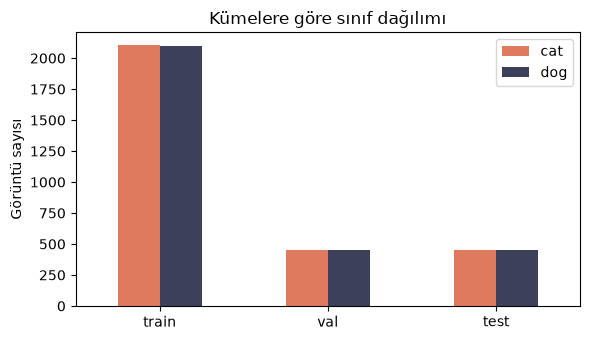

In [7]:
# --- Sınıf dengesi ---
balance = pd.DataFrame(
    {split: Counter(split_labels) for split, (_, split_labels) in splits.items()}
).T[CLASS_NAMES]
balance["toplam"] = balance.sum(axis=1)
balance["dog_oranı"] = (balance["dog"] / balance["toplam"]).round(3)
display(balance)

ax = balance[CLASS_NAMES].plot(kind="bar", figsize=(6, 3.5), color=["#e07a5f", "#3d405b"], rot=0)
ax.set_title("Kümelere göre sınıf dağılımı")
ax.set_ylabel("Görüntü sayısı")
plt.tight_layout()
plt.show()

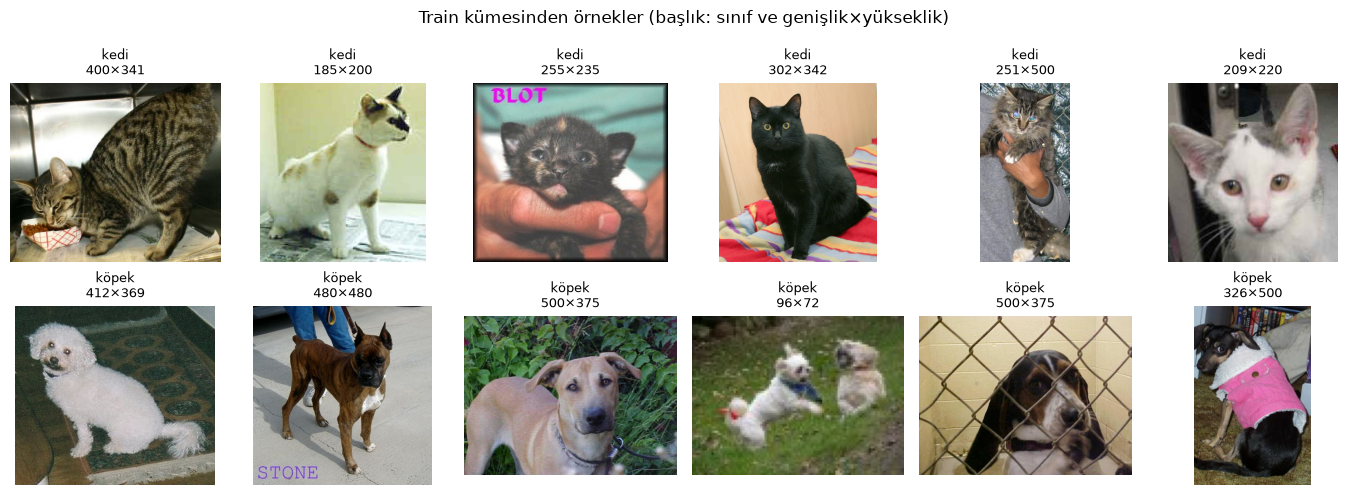

In [8]:
# --- Her sınıftan örnek görüntüler (train kümesinden) ---
rng = random.Random(SEED)
n_per_class = 6
fig, axes = plt.subplots(2, n_per_class, figsize=(2.3 * n_per_class, 5))
for row, cls in enumerate(CLASS_NAMES):
    cls_files = sorted((DATA_DIR / "train" / cls).iterdir())
    for col, p in enumerate(rng.sample(cls_files, n_per_class)):
        with Image.open(p) as img:
            axes[row, col].imshow(img.convert("RGB"))
            axes[row, col].set_title(f"{CLASS_NAMES_TR[cls]}\n{img.size[0]}×{img.size[1]}", fontsize=9)
        axes[row, col].axis("off")
plt.suptitle("Train kümesinden örnekler (başlık: sınıf ve genişlik×yükseklik)")
plt.tight_layout()
plt.show()

sınıf                   cat      dog
genişlik     count  2103.00  2097.00
             mean    413.51   401.25
             std     107.02   106.12
             min      60.00    58.00
             25%     336.50   321.00
             50%     480.00   427.00
             75%     500.00   500.00
             max     500.00   500.00
yükseklik    count  2103.00  2097.00
             mean    356.19   368.10
             std      94.18    95.80
             min      45.00    50.00
             25%     305.00   314.00
             50%     375.00   375.00
             75%     400.00   439.00
             max     500.00   500.00
en_boy_oranı count  2103.00  2097.00
             mean      1.20     1.12
             std       0.29     0.28
             min       0.38     0.48
             25%       0.99     0.88
             50%       1.33     1.19
             75%       1.33     1.33
             max       3.19     2.48

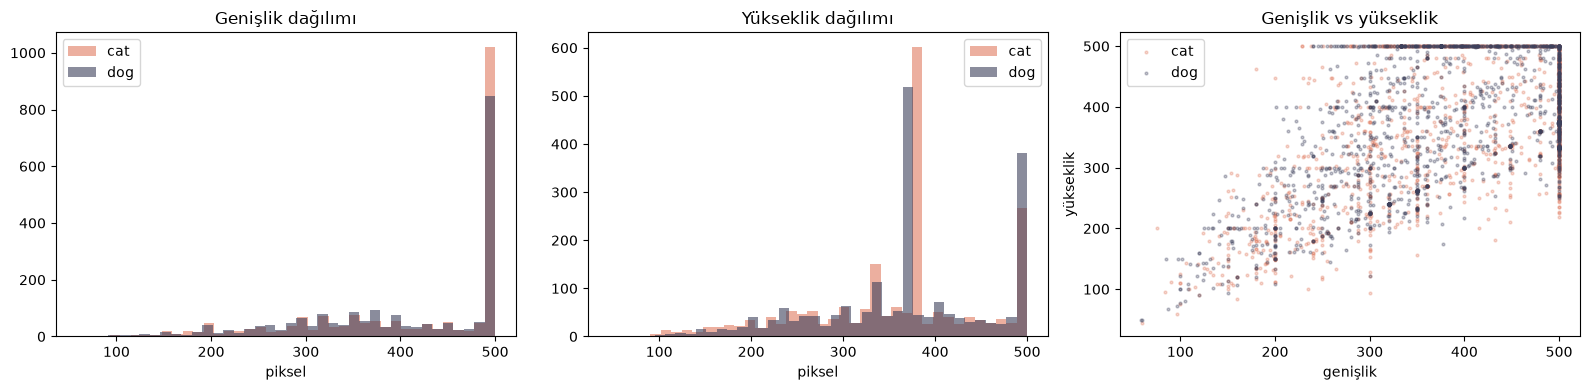

In [9]:
# --- Görüntü boyutlarının dağılımı (train) ---
# Image.open yalnızca dosya başlığını okur; .size için tüm pikselleri çözmek gerekmez, bu yüzden hızlıdır.
size_records = []
for cls in CLASS_NAMES:
    for p in (DATA_DIR / "train" / cls).iterdir():
        with Image.open(p) as img:
            w, h = img.size
        size_records.append({"sınıf": cls, "genişlik": w, "yükseklik": h})
sizes = pd.DataFrame(size_records)
sizes["en_boy_oranı"] = sizes["genişlik"] / sizes["yükseklik"]

display(sizes.groupby("sınıf")[["genişlik", "yükseklik", "en_boy_oranı"]].describe().T.round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for cls, color in zip(CLASS_NAMES, ["#e07a5f", "#3d405b"]):
    s = sizes[sizes["sınıf"] == cls]
    axes[0].hist(s["genişlik"], bins=40, alpha=0.6, label=cls, color=color)
    axes[1].hist(s["yükseklik"], bins=40, alpha=0.6, label=cls, color=color)
    axes[2].scatter(s["genişlik"], s["yükseklik"], s=4, alpha=0.3, label=cls, color=color)
axes[0].set_title("Genişlik dağılımı")
axes[1].set_title("Yükseklik dağılımı")
axes[2].set_title("Genişlik vs yükseklik")
axes[0].set_xlabel("piksel")
axes[1].set_xlabel("piksel")
axes[2].set_xlabel("genişlik")
axes[2].set_ylabel("yükseklik")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

**Gözlemler:** Sınıflar dengeli (~%50/%50), bu yüzden accuracy uygun bir metrik. Görüntü boyutları ve en-boy oranları değişken (çoğu ~500 px), o yüzden hepsini sabit kare boyuta getireceğiz. Fotoğraflar gerçek hayattan ve gürültülü: farklı arka planlar, pozlar ve ışık koşulları var.

## 4. Veri pipeline'ı

JPEG dosyalarını tensör batch'lerine çeviriyoruz:
- `Resize`: Bir batch'teki tüm görüntüler aynı boyutta olmalı. CNN için 128×128, transfer learning için 224×224 kullanıyoruz.
- `ToImage` → `ToDtype(float32, scale=True)`: PIL görüntüsü `[C, H, W]` tensöre çevrilir, 0–255 aralığı 0–1'e ölçeklenir.
- `Normalize`: ImageNet ortalama/std'si ile `(x - mean) / std`. Önceden eğitilmiş model bu normalizasyonu bekler.
- `ImageFolder`: Etiketi klasör adından verir (`cat → 0`, `dog → 1`).
- `DataLoader`: Batch oluşturur (32), train'de karıştırır, `num_workers` ile paralel yükler, `pin_memory` ile GPU'ya kopyalamayı hızlandırır.

Test loader'ı burada oluşturmuyoruz; o 8. bölümde gelecek.

In [10]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def make_eval_transform(size: int) -> v2.Compose:
    # Augmentation İÇERMEYEN, deterministik dönüşüm (val/test ve Model 1'in train'i için)
    return v2.Compose([
        v2.Resize((size, size), antialias=True),     # sabit kare boyut
        v2.ToImage(),                                # PIL → tensör [C, H, W], uint8
        v2.ToDtype(torch.float32, scale=True),       # uint8 [0,255] → float32 [0,1]
        v2.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),  # kanal bazında standardizasyon
    ])


def make_loader(dataset, shuffle: bool) -> DataLoader:
    # Her DataLoader'a kendi seed'li üretecini veriyoruz → karıştırma sırası tekrarlanabilir
    g = torch.Generator()
    g.manual_seed(SEED)
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
        worker_init_fn=seed_worker,
        generator=g,
    )


eval_tf_cnn = make_eval_transform(IMG_SIZE_CNN)

train_ds_cnn = datasets.ImageFolder(DATA_DIR / "train", transform=eval_tf_cnn)
val_ds_cnn = datasets.ImageFolder(DATA_DIR / "val", transform=eval_tf_cnn)

train_loader_cnn = make_loader(train_ds_cnn, shuffle=True)   # train: her epoch karıştır
val_loader_cnn = make_loader(val_ds_cnn, shuffle=False)      # val: sıra önemli değil, karıştırmaya gerek yok

print("Sınıf → indeks:", train_ds_cnn.class_to_idx)
print(f"Train: {len(train_ds_cnn)} görüntü, {len(train_loader_cnn)} batch")
print(f"Val  : {len(val_ds_cnn)} görüntü, {len(val_loader_cnn)} batch")

Sınıf → indeks: {'cat': 0, 'dog': 1}
Train: 4200 görüntü, 132 batch
Val  : 900 görüntü, 29 batch


In [11]:
images, labels = next(iter(train_loader_cnn))
print("images.shape:", tuple(images.shape), " dtype:", images.dtype)
print("labels.shape:", tuple(labels.shape), " dtype:", labels.dtype)
print("labels (ilk 10):", labels[:10].tolist())
print(f"Piksel değer aralığı (normalize sonrası): min={images.min():.2f}, max={images.max():.2f}, ortalama={images.mean():.2f}")

images.shape: (32, 3, 128, 128)  dtype: torch.float32
labels.shape: (32,)  dtype: torch.int64
labels (ilk 10): [0, 0, 1, 1, 1, 0, 1, 1, 0, 0]
Piksel değer aralığı (normalize sonrası): min=-2.12, max=2.64, ortalama=0.03


**`[32, 3, 128, 128]` = `[B, C, H, W]`:** batch boyutu (32 görüntü), kanal (RGB), yükseklik, genişlik.

⚠️ PyTorch kanalı **önde** tutar. NumPy, PIL ve matplotlib ise `[H, W, C]` kullanır. Bu yüzden çizmeden önce `permute(1, 2, 0)` gerekir. `labels` her görüntü için 0/1 içeren `[32]` boyutlu bir vektördür.

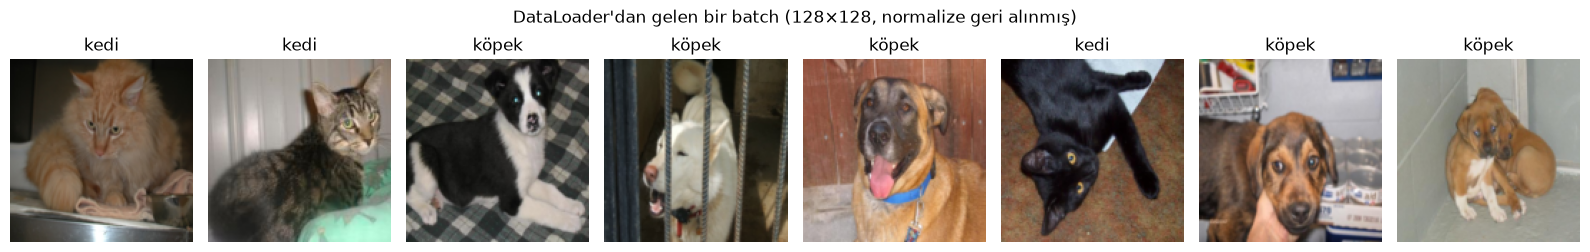

In [12]:
def denormalize(img_tensor: torch.Tensor) -> np.ndarray:
    # Normalize işlemini tersine çevirir: x * std + mean. Sonra [C,H,W] → [H,W,C] (matplotlib için)
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    img = img_tensor.cpu() * std + mean
    return img.clamp(0, 1).permute(1, 2, 0).numpy()   # sayısal hatalar için [0,1]'e kırp


fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for i, ax in enumerate(axes):
    ax.imshow(denormalize(images[i]))
    ax.set_title(CLASS_NAMES_TR[CLASS_NAMES[labels[i]]])
    ax.axis("off")
plt.suptitle("DataLoader'dan gelen bir batch (128×128, normalize geri alınmış)")
plt.tight_layout()
plt.show()

## 5. Model 1: Sıfırdan CNN

**Mimari:** 4 blok `Conv2d → BatchNorm2d → ReLU → MaxPool2d`. Kanallar 3→32→64→128→256 diye artarken boyut 128→8'e iner. Ardından `AdaptiveAvgPool2d(1)` ve tek çıkışlı `Linear` (logit) gelir.
- Conv: yerel desenleri öğrenir. BatchNorm: eğitimi kararlı hale getirir. ReLU: doğrusal olmama sağlar. MaxPool: boyutu yarıya indirir.
- BatchNorm kendi kaydırma parametresine sahip olduğu için Conv'da `bias=False` kullanıyoruz.

**Neden sonda sigmoid yok?** `BCEWithLogitsLoss` sigmoid'i kendi içinde, sayısal olarak kararlı biçimde uygular. Ayrı sigmoid + `BCELoss`, uç değerlerde `log(0)` sorununa yol açabilir. Modele sigmoid eklersek sigmoid iki kez uygulanır. Bu yüzden model ham **logit** döndürür; olasılık gerektiğinde `torch.sigmoid` kullanırız.

In [13]:
class SimpleCNN(nn.Module):
    # 4 bloklu basit CNN. dropout=0.0 → Model 1, dropout>0 → Model 2

    def __init__(self, dropout: float = 0.0):
        super().__init__()  # nn.Module'ün kurucusunu çağır (parametre takibi vb. için şart)

        def conv_block(in_ch: int, out_ch: int) -> nn.Sequential:
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),  # padding=1 → H,W korunur
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(kernel_size=2),  # H ve W yarıya iner
            )

        self.features = nn.Sequential(
            conv_block(3, 32),     # [B,3,128,128]  → [B,32,64,64]
            conv_block(32, 64),    # → [B,64,32,32]
            conv_block(64, 128),   # → [B,128,16,16]
            conv_block(128, 256),  # → [B,256,8,8]
        )
        self.pool = nn.AdaptiveAvgPool2d(1)  # → [B,256,1,1]
        self.classifier = nn.Sequential(
            nn.Flatten(),                    # → [B,256]
            nn.Dropout(p=dropout),           # p=0 iken hiçbir şey yapmaz
            nn.Linear(256, 1),               # → [B,1] (logit; sigmoid YOK)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Verinin model içinde izlediği yol
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)


def count_parameters(model: nn.Module):
    # Toplam ve eğitilebilir (requires_grad=True) parametre sayısını döndürür
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


set_seed(SEED)  # ağırlıkların başlangıç değerleri tekrarlanabilir olsun
model1 = SimpleCNN(dropout=0.0).to(device)
print(model1)

total, trainable = count_parameters(model1)
print(f"\nToplam parametre     : {total:,}")
print(f"Eğitilebilir parametre: {trainable:,}")

# Sağlama: sahte bir batch'i modelden geçirip çıktı şekline bakalım
with torch.no_grad():
    print("\nÇıktı şekli:", tuple(model1(images[:4].to(device)).shape), "→ her görüntü için tek bir logit")

SimpleCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, paddin


Çıktı şekli: (4, 1) → her görüntü için tek bir logit


### Conv parametre sayısını elle hesaplama

$$\text{parametre} = k \cdot k \cdot C_{in} \cdot C_{out} \; (+ \; C_{out} \text{ bias varsa})$$

1. Conv: $3 \cdot 3 \cdot 3 \cdot 32 = 864$ (bias olsaydı 896). BatchNorm her kanal için 2 parametre (γ, β) tutar: $2 \cdot 32 = 64$.

In [14]:
def conv_params(k: int, c_in: int, c_out: int, bias: bool) -> int:
    return k * k * c_in * c_out + (c_out if bias else 0)


first_conv = model1.features[0][0]   # 1. bloğun Conv2d katmanı
second_conv = model1.features[1][0]  # 2. bloğun Conv2d katmanı

for name, layer, (k, cin, cout) in [("1. Conv", first_conv, (3, 3, 32)), ("2. Conv", second_conv, (3, 32, 64))]:
    manual = conv_params(k, cin, cout, bias=False)
    pytorch = sum(p.numel() for p in layer.parameters())
    print(f"{name}: elle = {k}*{k}*{cin}*{cout} = {manual:,}  |  PyTorch = {pytorch:,}  |  eşit mi? {manual == pytorch}")

bn = model1.features[0][1]
print(f"1. BatchNorm: elle = 2*32 = 64  |  PyTorch = {sum(p.numel() for p in bn.parameters())}")

1. Conv: elle = 3*3*3*32 = 864  |  PyTorch = 864  |  eşit mi? True
2. Conv: elle = 3*3*32*64 = 18,432  |  PyTorch = 18,432  |  eşit mi? True
1. BatchNorm: elle = 2*32 = 64  |  PyTorch = 64


### Eğitim ve değerlendirme döngüleri

`train_one_epoch`:
- `model.train()`: Eğitim modu. Dropout aktif olur, BatchNorm batch istatistiklerini kullanır ve günceller.
- `optimizer.zero_grad()`: Gradyanlar birikir; her adımda sıfırlanmalı.
- `model(images)` → `criterion(...)`: İleri yayılım ve loss hesabı.
- `loss.backward()`: Her parametrenin gradyanını hesaplar.
- `optimizer.step()`: Gradyanlarla ağırlıkları günceller.

`evaluate`:
- `model.eval()`: Dropout kapanır, BatchNorm kayıtlı istatistikleri kullanır.
- `torch.no_grad()`: Gradyan takibi yapılmaz; bellek ve zaman kazandırır.

Etiketler `BCEWithLogitsLoss` için `.float().unsqueeze(1)` ile `[B, 1]` yapılır. `logit > 0` ifadesi `olasılık > 0.5` ile aynıdır.

In [15]:
def set_bn_eval(model: nn.Module) -> None:
    # Modeldeki tüm BatchNorm katmanlarını eval moduna alır (Model 3'te kullanılacak; açıklama 7. bölümde)
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm):
            m.eval()


def train_one_epoch(model, loader, criterion, optimizer, device, bn_eval: bool = False):
    model.train()                 # eğitim modu: Dropout aktif, BatchNorm batch istatistiklerini kullanır/günceller
    if bn_eval:
        set_bn_eval(model)        # (Transfer learning için) BatchNorm'ları eval modunda tut

    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        # Veriyi modelin bulunduğu cihaza taşı; non_blocking + pin_memory ile kopyalama asenkron olur
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True).float().unsqueeze(1)  # [B] int → [B,1] float

        optimizer.zero_grad()              # 1) eski gradyanları sıfırla
        logits = model(images)             # 2) ileri yayılım: tahmin (logit) üret
        loss = criterion(logits, labels)   # 3) loss'u hesapla (sigmoid + BCE, içeride)
        loss.backward()                    # 4) geri yayılım: her parametrenin gradyanını hesapla
        optimizer.step()                   # 5) gradyanlarla parametreleri güncelle

        # İstatistikler: loss batch ortalaması olduğu için batch boyutuyla çarpıp topluyoruz
        running_loss += loss.item() * images.size(0)
        preds = (logits > 0).float()       # logit > 0  ⇔  olasılık > 0.5  ⇔  "köpek"
        correct += (preds == labels).sum().item()
        total += images.size(0)

    return running_loss / total, correct / total


def evaluate(model, loader, criterion, device):
    model.eval()                  # değerlendirme modu: Dropout kapalı, BatchNorm kayıtlı istatistikleri kullanır
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():         # gradyan takibi yok → daha az bellek, daha hızlı
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True).float().unsqueeze(1)
            logits = model(images)
            loss = criterion(logits, labels)
            running_loss += loss.item() * images.size(0)
            correct += ((logits > 0).float() == labels).sum().item()
            total += images.size(0)
    return running_loss / total, correct / total


def predict(model, loader, device):
    # Tüm loader için köpek olasılıklarını (sigmoid) ve gerçek etiketleri döndürür (8. bölümde kullanılacak)
    model.eval()
    all_probs, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            logits = model(images.to(device, non_blocking=True))
            all_probs.append(torch.sigmoid(logits).squeeze(1).cpu())  # logit → olasılık
            all_labels.append(labels)
    return torch.cat(all_probs).numpy(), torch.cat(all_labels).numpy()

### `fit`: checkpoint, early stopping, LR zamanlayıcısı

- Val_loss iyileştiğinde ağırlıklar (`state_dict`) kaydedilir. Sonunda en iyi model geri yüklenir.
- **Early stopping:** Val_loss `patience` epoch boyunca iyileşmezse eğitim durur.
- **`ReduceLROnPlateau`** (isteğe bağlı): Val_loss takılınca learning rate'i yarıya indirir.

Val_loss'u takip ediyoruz, çünkü modelin emin olarak yaptığı hataları da yansıttığı için overfitting'i accuracy'den önce gösterir.

In [16]:
def fit(model, train_loader, val_loader, criterion, optimizer, epochs: int, patience: int,
        save_path: Path, bn_eval: bool = False, best_val_loss: float = float("inf"), scheduler=None):
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    epochs_without_improvement = 0
    if best_val_loss == float("inf") and save_path.exists():
        save_path.unlink()  # önceki çalıştırmadan kalan checkpoint yanlışlıkla yüklenmesin
    start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device, bn_eval)
        val_loss, val_acc = evaluate(model, val_loader, criterion, device)
        for key, value in zip(history, [train_loss, train_acc, val_loss, val_acc]):
            history[key].append(value)
        lr = optimizer.param_groups[0]["lr"]  # bu epoch'ta kullanılan learning rate
        if scheduler is not None:
            scheduler.step(val_loss)          # val_loss iyileşmiyorsa learning rate'i düşür

        if val_loss < best_val_loss:
            # Yeni en iyi model: ağırlıkları kaydet, sayacı sıfırla
            best_val_loss = val_loss
            epochs_without_improvement = 0
            torch.save(model.state_dict(), save_path)
            note = "✓ en iyi, kaydedildi"
        else:
            epochs_without_improvement += 1
            note = f"iyileşme yok ({epochs_without_improvement}/{patience})"

        print(f"Epoch {epoch:2d}/{epochs} | train loss {train_loss:.4f} acc {train_acc:.4f} | "
              f"val loss {val_loss:.4f} acc {val_acc:.4f} | lr {lr:.0e} | {note}")

        if epochs_without_improvement >= patience:
            print(f"Early stopping: {patience} epoch boyunca val_loss iyileşmedi.")
            break

    if device.type == "cuda":
        torch.cuda.synchronize()  # GPU işlemleri asenkron; süreyi doğru ölçmek için bitmelerini bekle
    elapsed = time.perf_counter() - start

    # En iyi ağırlıkları geri yükle (val_loss hiç iyileşmediyse, ör. NaN, dosya yoktur)
    if save_path.exists():
        model.load_state_dict(torch.load(save_path, map_location=device, weights_only=True))
    else:
        print("Uyarı: hiç checkpoint kaydedilmedi, son epoch'un ağırlıkları kullanılıyor.")
    print(f"Süre: {elapsed:.1f} sn | en iyi val_loss: {best_val_loss:.4f}")
    return history, elapsed, best_val_loss


def plot_history(histories: dict, title: str, phase_boundary: int = None):
    # histories: {"model adı": history} → loss ve accuracy eğrileri
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for i, (name, h) in enumerate(histories.items()):
        color = f"C{i}"
        epochs_range = range(1, len(h["train_loss"]) + 1)
        for ax, metric in zip(axes, ["loss", "acc"]):
            ax.plot(epochs_range, h[f"train_{metric}"], "--", color=color, label=f"{name} train")
            ax.plot(epochs_range, h[f"val_{metric}"], "-o", color=color, markersize=4, label=f"{name} val")
    for ax, ylabel in zip(axes, ["Loss (BCE)", "Accuracy"]):
        ax.set_xlabel("Epoch")
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
        if phase_boundary:
            ax.axvline(phase_boundary + 0.5, color="gray", linestyle=":", label="fine-tuning başlangıcı")
        ax.legend()  # axvline'dan sonra çağrılmalı, yoksa çizgi lejantta görünmez
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

### Model 1'i eğitme

`BCEWithLogitsLoss`, `Adam(lr=1e-3)`, `ReduceLROnPlateau(factor=0.5, patience=2)` ve early stopping `patience=5`. Augmentation ve dropout yok.

In [17]:
EPOCHS_CNN = 30
PATIENCE_CNN = 5

criterion = nn.BCEWithLogitsLoss()
optimizer1 = torch.optim.Adam(model1.parameters(), lr=1e-3)
scheduler1 = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer1, mode="min", factor=0.5, patience=2)

history1, time1, best_val_loss1 = fit(
    model1, train_loader_cnn, val_loader_cnn, criterion, optimizer1,
    epochs=EPOCHS_CNN, patience=PATIENCE_CNN, save_path=MODELS_DIR / "model1_cnn.pth", scheduler=scheduler1,
)

Epoch  1/30 | train loss 0.6488 acc 0.6217 | val loss 0.8166 acc 0.5533 | lr 1e-03 | ✓ en iyi, kaydedildi


Epoch  2/30 | train loss 0.6138 acc 0.6629 | val loss 0.6910 acc 0.5811 | lr 1e-03 | ✓ en iyi, kaydedildi


Epoch  3/30 | train loss 0.5796 acc 0.6914 | val loss 0.5768 acc 0.6922 | lr 1e-03 | ✓ en iyi, kaydedildi


Epoch  4/30 | train loss 0.5671 acc 0.7090 | val loss 0.6330 acc 0.6644 | lr 1e-03 | iyileşme yok (1/5)


Epoch  5/30 | train loss 0.5354 acc 0.7307 | val loss 0.6432 acc 0.6567 | lr 1e-03 | iyileşme yok (2/5)


Epoch  6/30 | train loss 0.5155 acc 0.7512 | val loss 0.5956 acc 0.6800 | lr 1e-03 | iyileşme yok (3/5)


... (20 outputs left out)

Epoch 27/30 | train loss 0.1883 acc 0.9317 | val loss 0.4524 acc 0.7922 | lr 6e-05 | iyileşme yok (2/5)


Epoch 28/30 | train loss 0.1840 acc 0.9367 | val loss 0.3628 acc 0.8267 | lr 6e-05 | iyileşme yok (3/5)


Epoch 29/30 | train loss 0.1746 acc 0.9386 | val loss 0.3228 acc 0.8689 | lr 3e-05 | ✓ en iyi, kaydedildi


Epoch 30/30 | train loss 0.1702 acc 0.9443 | val loss 0.3247 acc 0.8689 | lr 3e-05 | iyileşme yok (1/5)
Süre: 115.7 sn | en iyi val_loss: 0.3228


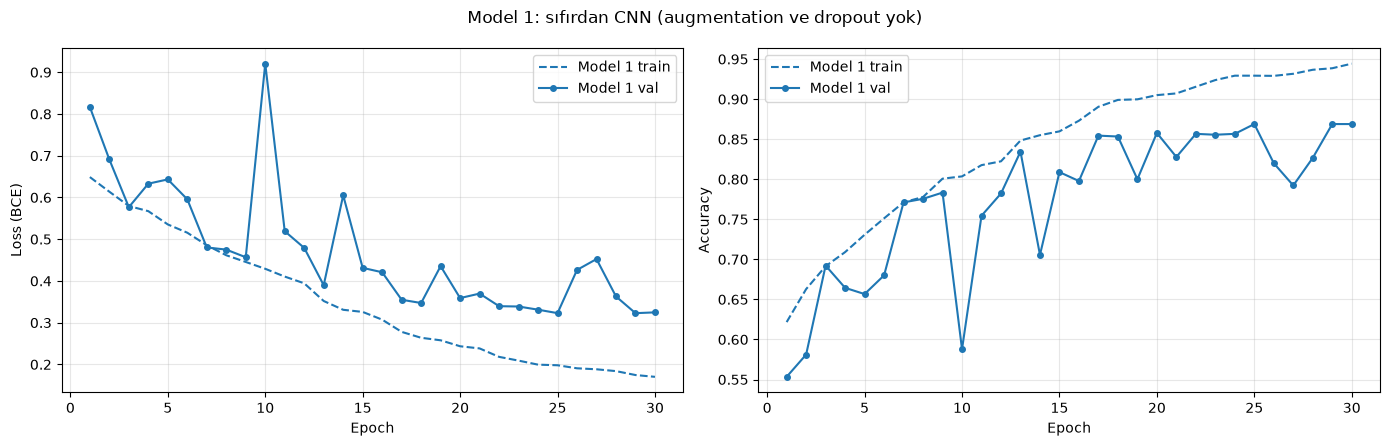

En iyi epoch (29): train acc 0.939, val acc 0.869, fark +0.070 | train loss 0.175, val loss 0.323
Son epoch (30): train acc 0.944, val acc 0.869, fark +0.075 | train loss 0.170, val loss 0.325


In [18]:
plot_history({"Model 1": history1}, "Model 1: sıfırdan CNN (augmentation ve dropout yok)")


def overfitting_report(h: dict) -> None:
    # En iyi (en düşük val_loss) epoch'taki ve son epoch'taki train/val farkını yazdırır
    best = int(np.argmin(h["val_loss"]))
    last = len(h["val_loss"]) - 1
    for name, i in [("En iyi epoch", best), ("Son epoch", last)]:
        print(f"{name} ({i + 1}): train acc {h['train_acc'][i]:.3f}, val acc {h['val_acc'][i]:.3f}, "
              f"fark {h['train_acc'][i] - h['val_acc'][i]:+.3f} | "
              f"train loss {h['train_loss'][i]:.3f}, val loss {h['val_loss'][i]:.3f}")


overfitting_report(history1)

### Overfitting yorumu

Overfitting, modelin train verisini ezberlemesidir: Train loss düşmeye devam ederken val loss takılır ya da yükselir ve iki eğri arasındaki fark açılır.

Yerel çalıştırmamızda (`SUBSET_SIZE = 6000`) train accuracy %94'e çıktı, val accuracy ise ~%87'de kaldı. Fark ~7 puan ve açılmaya devam ediyor. Küçük val setinde (900 görüntü) eğri dalgalı; learning rate düştükçe dalgalanma azalıyor. Bir sonraki bölümde overfitting'i augmentation ve dropout ile azaltacağız.

## 6. Model 2: Augmentation + Dropout

- **Augmentation:** Her epoch'ta farklı rastgele kırpma (`RandomResizedCrop`), yatay çevirme, ±15° döndürme ve renk oynaması (`ColorJitter`) uygulanır. Model aynı görüntüyü hiç aynı haliyle görmediği için ezberleyemez.
- **Dropout (0.3):** Eğitimde nöronların bir kısmını rastgele kapatır, böylece model tek bir özelliğe aşırı güvenemez.

**Augmentation neden sadece train'de?** Amacı öğrenmeyi çeşitlendirmek. Val ve test ise modelin gerçek, değiştirilmemiş görüntülerdeki başarısını deterministik olarak ölçmeli. Rastgele dönüşüm uygulanırsa ölçüm hem gerçekçi olmaz hem de her çalıştırmada değişir.

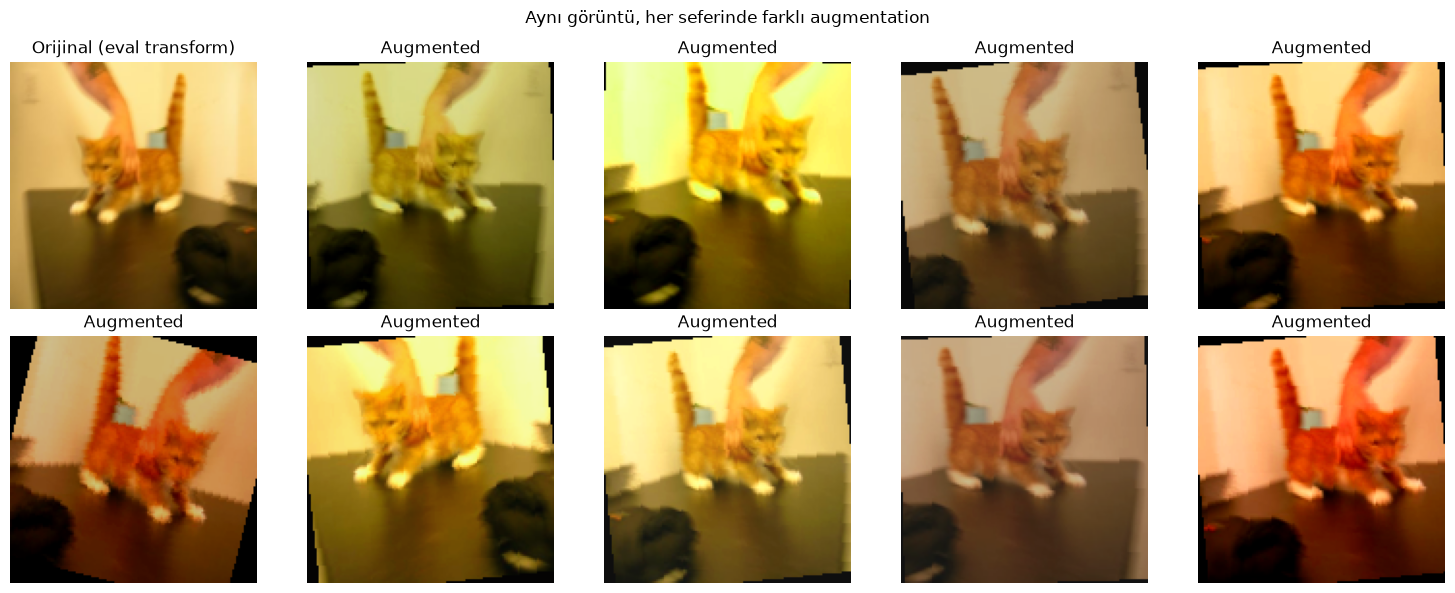

In [19]:
def make_train_aug_transform(size: int) -> v2.Compose:
    # Sadece TRAIN için: rastgele dönüşümler + aynı tensör/normalize adımları
    return v2.Compose([
        v2.RandomResizedCrop(size, scale=(0.7, 1.0), antialias=True),  # rastgele kırp + yeniden boyutlandır
        v2.RandomHorizontalFlip(p=0.5),                                 # %50 yatay çevirme
        v2.RandomRotation(degrees=15),                                  # ±15° döndürme
        v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),  # renk/ışık oynamaları
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])


train_aug_tf_cnn = make_train_aug_transform(IMG_SIZE_CNN)

# Aynı görüntünün augmented hâllerini görelim
sample_path, _ = datasets.ImageFolder(DATA_DIR / "train").samples[0]
with Image.open(sample_path) as img:
    sample_img = img.convert("RGB")

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.ravel()
axes[0].imshow(denormalize(eval_tf_cnn(sample_img)))
axes[0].set_title("Orijinal (eval transform)")
for ax in axes[1:]:
    ax.imshow(denormalize(train_aug_tf_cnn(sample_img)))  # her çağrıda farklı rastgele dönüşüm
    ax.set_title("Augmented")
for ax in axes:
    ax.axis("off")
plt.suptitle("Aynı görüntü, her seferinde farklı augmentation")
plt.tight_layout()
plt.show()

Augmentation öğrenmeyi yavaşlattığı için Model 2'ye daha fazla epoch ve patience veriyoruz. Val loader değişmiyor.

In [20]:
EPOCHS_CNN_AUG = 40
PATIENCE_CNN_AUG = 6
DROPOUT_M2 = 0.3  # sınıflandırıcıdan önceki dropout oranı

train_ds_aug = datasets.ImageFolder(DATA_DIR / "train", transform=train_aug_tf_cnn)  # yalnızca train değişti
train_loader_aug = make_loader(train_ds_aug, shuffle=True)

set_seed(SEED)
model2 = SimpleCNN(dropout=DROPOUT_M2).to(device)
optimizer2 = torch.optim.Adam(model2.parameters(), lr=1e-3)
scheduler2 = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer2, mode="min", factor=0.5, patience=2)

history2, time2, best_val_loss2 = fit(
    model2, train_loader_aug, val_loader_cnn, criterion, optimizer2,
    epochs=EPOCHS_CNN_AUG, patience=PATIENCE_CNN_AUG, save_path=MODELS_DIR / "model2_cnn_aug.pth", scheduler=scheduler2,
)

Epoch  1/40 | train loss 0.6676 acc 0.6010 | val loss 0.6411 acc 0.6189 | lr 1e-03 | ✓ en iyi, kaydedildi


Epoch  2/40 | train loss 0.6281 acc 0.6505 | val loss 0.6303 acc 0.6411 | lr 1e-03 | ✓ en iyi, kaydedildi


Epoch  3/40 | train loss 0.6099 acc 0.6660 | val loss 0.6982 acc 0.6167 | lr 1e-03 | iyileşme yok (1/6)


Epoch  4/40 | train loss 0.5977 acc 0.6850 | val loss 0.7267 acc 0.5900 | lr 1e-03 | iyileşme yok (2/6)


Epoch  5/40 | train loss 0.5817 acc 0.6938 | val loss 0.6618 acc 0.6456 | lr 1e-03 | iyileşme yok (3/6)


Epoch  6/40 | train loss 0.5550 acc 0.7179 | val loss 0.6261 acc 0.6589 | lr 5e-04 | ✓ en iyi, kaydedildi


... (30 outputs left out)

Epoch 37/40 | train loss 0.3117 acc 0.8655 | val loss 0.6160 acc 0.7200 | lr 3e-04 | iyileşme yok (2/6)


Epoch 38/40 | train loss 0.3095 acc 0.8710 | val loss 0.3412 acc 0.8467 | lr 3e-04 | iyileşme yok (3/6)


Epoch 39/40 | train loss 0.2923 acc 0.8771 | val loss 0.3214 acc 0.8622 | lr 1e-04 | ✓ en iyi, kaydedildi


Epoch 40/40 | train loss 0.2883 acc 0.8810 | val loss 0.3495 acc 0.8622 | lr 1e-04 | iyileşme yok (1/6)
Süre: 316.1 sn | en iyi val_loss: 0.3214


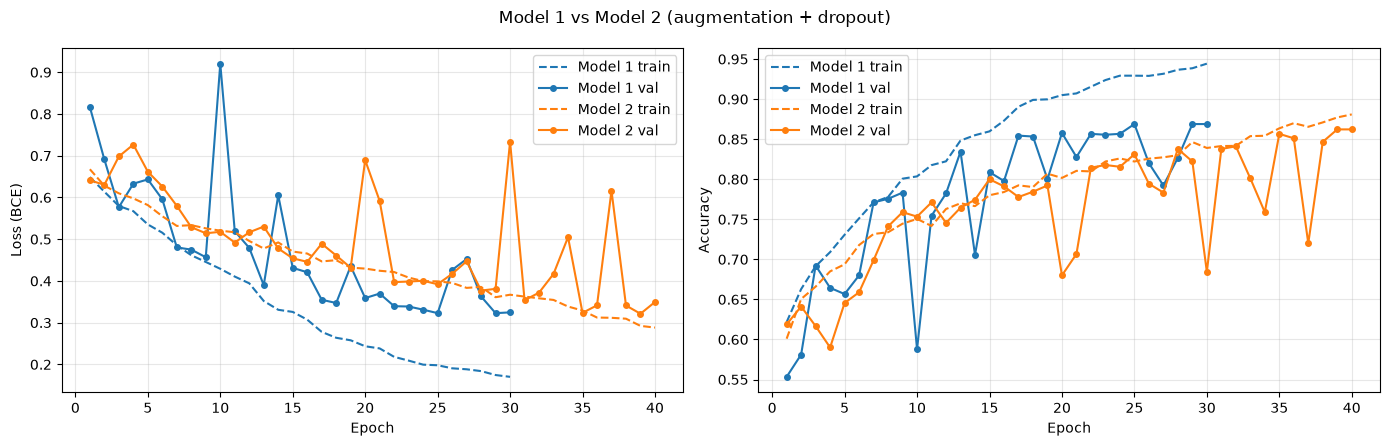

Model 1:
En iyi epoch (29): train acc 0.939, val acc 0.869, fark +0.070 | train loss 0.175, val loss 0.323
Son epoch (30): train acc 0.944, val acc 0.869, fark +0.075 | train loss 0.170, val loss 0.325
Model 2:
En iyi epoch (39): train acc 0.877, val acc 0.862, fark +0.015 | train loss 0.292, val loss 0.321
Son epoch (40): train acc 0.881, val acc 0.862, fark +0.019 | train loss 0.288, val loss 0.350


In [21]:
plot_history({"Model 1": history1, "Model 2": history2}, "Model 1 vs Model 2 (augmentation + dropout)")
print("Model 1:")
overfitting_report(history1)
print("Model 2:")
overfitting_report(history2)

### Model 1 ve Model 2

Yerel çalıştırmada train/val farkı ~7 puandan ~1,5 puana indi. Val accuracy'ler benzer (~%86–87), ancak Model 2 test setinde daha iyi genelleşiyor. Model 2 40. epoch'ta hâlâ iyileşiyordu. Bedeli daha uzun eğitim; parametre sayısı ise değişmedi.

## 7. Model 3: Transfer learning (MobileNetV2)

ImageNet'te eğitilmiş MobileNetV2 genel görsel özellikleri (kenar, doku, göz, kulak) zaten öğrenmiş durumda. Bu bilgiyi az veriyle kendi görevimize uyarlıyoruz.

1. **Feature extraction:** Tüm parametreler dondurulur (`requires_grad=False`). Son katman tek çıkışlı yeni bir `Linear` ile değiştirilir ve yalnızca o eğitilir.
2. **Fine-tuning:** Son 3 blok çözülür ve daha düşük learning rate (`1e-4`) ile eğitime devam edilir; büyük adımlar önceden öğrenilmiş ağırlıkları bozar.

**Optimizer'a neden sadece `requires_grad=True` parametreler?** Hangi parametrelerin eğitildiği açık olur ve Adam donuk parametreler için gereksiz bellek ayırmaz. Fine-tuning'e geçerken **yeni optimizer** gerekir; eskisi sonradan çözülen parametreleri tanımaz.

**BatchNorm neden eval modunda kalır?** `requires_grad=False` yalnızca γ ve β'yı dondurur. Running mean/var ise `train()` modunda her ileri geçişte güncellenmeye devam eder. Küçük batch'lerle güncellenmeleri ImageNet'ten gelen istatistikleri bozar ve donuk katmanların beklediği dağılımı kaydırır. Bu yüzden `model.train()` sonrasında `set_bn_eval(model)` çağrılıyor.

In [22]:
# Transfer learning için 224×224 dataset/loader'lar. Train'de aynı augmentation tarifini 224'te kullanıyoruz.
eval_tf_tl = make_eval_transform(IMG_SIZE_TL)
train_aug_tf_tl = make_train_aug_transform(IMG_SIZE_TL)

train_ds_tl = datasets.ImageFolder(DATA_DIR / "train", transform=train_aug_tf_tl)
val_ds_tl = datasets.ImageFolder(DATA_DIR / "val", transform=eval_tf_tl)
train_loader_tl = make_loader(train_ds_tl, shuffle=True)
val_loader_tl = make_loader(val_ds_tl, shuffle=False)

UNFREEZE_BLOCKS = 3  # fine-tuning'de çözülecek son blok sayısı


def build_mobilenet(pretrained: bool = True) -> nn.Module:
    # weights="DEFAULT" → torchvision'daki en iyi ImageNet ağırlıkları; pretrained=False ise rastgele başlar
    model = models.mobilenet_v2(weights="DEFAULT" if pretrained else None)
    # Orijinal sınıflandırıcı: Sequential(Dropout(0.2), Linear(1280 → 1000)). Son Linear'ı değiştiriyoruz.
    model.classifier[1] = nn.Linear(model.last_channel, 1)  # 1280 → 1 (logit)
    return model


set_seed(SEED)
model3 = build_mobilenet(pretrained=True)

# 1) Önce TÜM parametreleri dondur...
for param in model3.parameters():
    param.requires_grad = False
# 2) ...sonra sadece yeni sınıflandırıcıyı eğitilebilir yap
for param in model3.classifier.parameters():
    param.requires_grad = True
model3 = model3.to(device)

print(model3.classifier)
total, trainable = count_parameters(model3)
print(f"Toplam parametre: {total:,} | Eğitilebilir: {trainable:,} (= 1280 ağırlık + 1 bias)")

Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=1, bias=True)
)
Toplam parametre: 2,225,153 | Eğitilebilir: 1,281 (= 1280 ağırlık + 1 bias)


In [23]:
EPOCHS_HEAD = 5
EPOCHS_FINETUNE = 5
PATIENCE_TL = 2
TL_PATH = MODELS_DIR / "model3_mobilenet.pth"

# Optimizer'a SADECE eğitilebilir parametreleri veriyoruz
optimizer3_head = torch.optim.Adam([p for p in model3.parameters() if p.requires_grad], lr=1e-3)

print("=== Aşama 1: sadece sınıflandırıcı ===")
history3_head, time3_head, best_val_loss3 = fit(
    model3, train_loader_tl, val_loader_tl, criterion, optimizer3_head,
    epochs=EPOCHS_HEAD, patience=PATIENCE_TL, save_path=TL_PATH, bn_eval=True,
)

=== Aşama 1: sadece sınıflandırıcı ===


Epoch  1/5 | train loss 0.2308 acc 0.9626 | val loss 0.0760 acc 0.9889 | lr 1e-03 | ✓ en iyi, kaydedildi


Epoch  2/5 | train loss 0.0928 acc 0.9767 | val loss 0.0480 acc 0.9922 | lr 1e-03 | ✓ en iyi, kaydedildi


Epoch  3/5 | train loss 0.0714 acc 0.9783 | val loss 0.0393 acc 0.9922 | lr 1e-03 | ✓ en iyi, kaydedildi


Epoch  4/5 | train loss 0.0613 acc 0.9800 | val loss 0.0341 acc 0.9911 | lr 1e-03 | ✓ en iyi, kaydedildi


Epoch  5/5 | train loss 0.0613 acc 0.9810 | val loss 0.0309 acc 0.9911 | lr 1e-03 | ✓ en iyi, kaydedildi
Süre: 80.1 sn | en iyi val_loss: 0.0309


In [24]:
# Son UNFREEZE_BLOCKS bloğu çöz. features[-1] son 1×1 Conv+BN+ReLU6 katmanı, öncekiler inverted residual blokları.
for block in model3.features[-UNFREEZE_BLOCKS:]:
    for param in block.parameters():
        param.requires_grad = True

total, trainable3 = count_parameters(model3)
print(f"Fine-tuning: eğitilebilir parametre {trainable3:,} / {total:,} ({trainable3 / total:.1%})")

# YENİ optimizer: artık çözülen blokları da içeriyor; daha düşük learning rate
optimizer3_ft = torch.optim.Adam([p for p in model3.parameters() if p.requires_grad], lr=1e-4)

print("\n=== Aşama 2: fine-tuning ===")
# best_val_loss'u aşama 1'den devralıyoruz: dosya sadece gerçekten daha iyi bir model bulunursa güncellenir
history3_ft, time3_ft, best_val_loss3 = fit(
    model3, train_loader_tl, val_loader_tl, criterion, optimizer3_ft,
    epochs=EPOCHS_FINETUNE, patience=PATIENCE_TL, save_path=TL_PATH, bn_eval=True,
    best_val_loss=best_val_loss3,
)

time3 = time3_head + time3_ft
history3 = {k: history3_head[k] + history3_ft[k] for k in history3_head}

Fine-tuning: eğitilebilir parametre 1,207,361 / 2,225,153 (54.3%)

=== Aşama 2: fine-tuning ===


Epoch  1/5 | train loss 0.0509 acc 0.9802 | val loss 0.0276 acc 0.9900 | lr 1e-04 | ✓ en iyi, kaydedildi


Epoch  2/5 | train loss 0.0390 acc 0.9850 | val loss 0.0298 acc 0.9889 | lr 1e-04 | iyileşme yok (1/2)


Epoch  3/5 | train loss 0.0353 acc 0.9862 | val loss 0.0326 acc 0.9889 | lr 1e-04 | iyileşme yok (2/2)
Early stopping: 2 epoch boyunca val_loss iyileşmedi.
Süre: 68.7 sn | en iyi val_loss: 0.0276


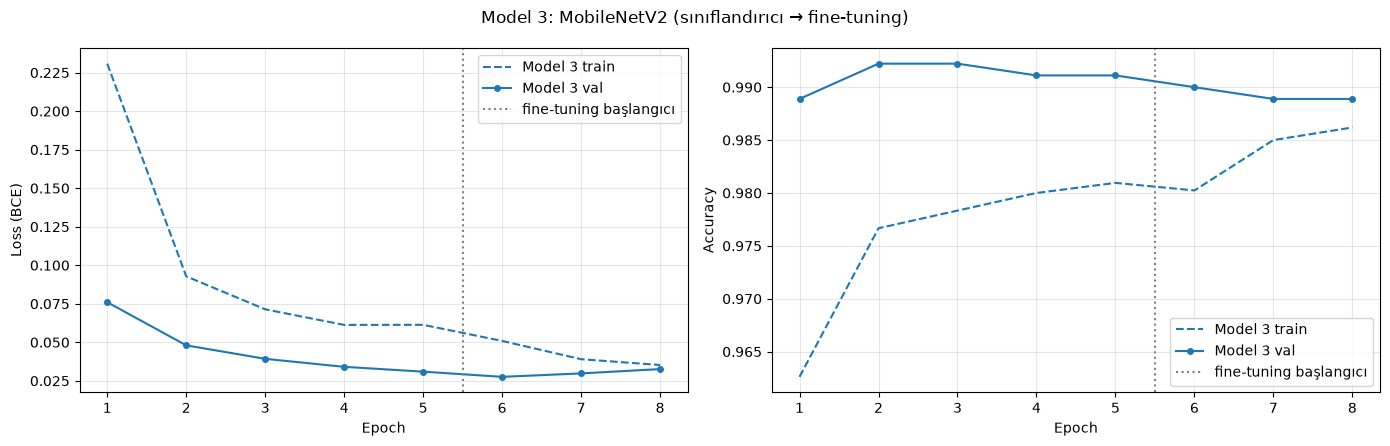

In [25]:
plot_history({"Model 3": history3}, "Model 3: MobileNetV2 (sınıflandırıcı → fine-tuning)",
             phase_boundary=len(history3_head["train_loss"]))

**Yorum:** Yalnızca 1.281 parametre eğitilmesine rağmen model daha ilk epoch'ta sıfırdan CNN'leri geride bırakıyor. Fine-tuning küçük bir ek kazanç sağlıyor; iyileşme olmazsa aşama 1'in modeli korunuyor. Train accuracy'nin val accuracy'den düşük olması, augmentation ve dropout yüzünden beklenen bir durum.

## 8. Test setinde değerlendirme

Test seti şimdi, **bir kez** kullanılıyor. Her model kendi eval dönüşümüyle değerlendiriliyor. "En iyi model" seçimi test accuracy'ye göre değil, **val accuracy**'ye göre yapılıyor; test sonucu yalnızca raporlanıyor. Model 3'ün eğitilebilir parametre sayısı fine-tuning aşamasına ait.

In [26]:
# Test dataset/loader'ları ancak şimdi oluşturuluyor
test_ds_cnn = datasets.ImageFolder(DATA_DIR / "test", transform=eval_tf_cnn)
test_ds_tl = datasets.ImageFolder(DATA_DIR / "test", transform=eval_tf_tl)
test_loader_cnn = make_loader(test_ds_cnn, shuffle=False)  # shuffle=False → sıra test_ds.samples ile aynı
test_loader_tl = make_loader(test_ds_tl, shuffle=False)

experiments = {
    "Model 1: CNN": dict(model=model1, val_loader=val_loader_cnn, test_loader=test_loader_cnn,
                         test_ds=test_ds_cnn, time=time1),
    "Model 2: CNN + aug + dropout": dict(model=model2, val_loader=val_loader_cnn, test_loader=test_loader_cnn,
                                         test_ds=test_ds_cnn, time=time2),
    "Model 3: MobileNetV2 (TL)": dict(model=model3, val_loader=val_loader_tl, test_loader=test_loader_tl,
                                      test_ds=test_ds_tl, time=time3),
}

rows = []
for name, exp in experiments.items():
    _, val_acc = evaluate(exp["model"], exp["val_loader"], criterion, device)
    test_loss, test_acc = evaluate(exp["model"], exp["test_loader"], criterion, device)
    probs, y_true = predict(exp["model"], exp["test_loader"], device)
    exp.update(val_acc=val_acc, test_acc=test_acc, probs=probs, y_true=y_true)
    total, trainable = count_parameters(exp["model"])
    rows.append({
        "Model": name,
        "Val accuracy": val_acc,
        "Test accuracy": test_acc,
        "Test loss": test_loss,
        "Eğitilebilir parametre": trainable,
        "Toplam parametre": total,
        "Eğitim süresi (sn)": exp["time"],
    })

results = pd.DataFrame(rows).set_index("Model")
display(results.style.format({
    "Val accuracy": "{:.2%}", "Test accuracy": "{:.2%}", "Test loss": "{:.4f}",
    "Eğitilebilir parametre": "{:,}", "Toplam parametre": "{:,}", "Eğitim süresi (sn)": "{:.0f}",
}))

best_name = results["Val accuracy"].idxmax()  # seçim validation'a göre
best = experiments[best_name]
print(f"Validation'a göre en iyi model: {best_name} → test accuracy {best['test_acc']:.2%}")

,Val accuracy,Test accuracy,Test loss,Eğitilebilir parametre,Toplam parametre,Eğitim süresi (sn)
Model,,,,,,
Model 1: CNN,86.89%,84.11%,0.3636,"389,153","389,153",116
Model 2: CNN + aug + dropout,86.22%,87.22%,0.3078,"389,153","389,153",316
Model 3: MobileNetV2 (TL),99.00%,98.44%,0.0371,"1,207,361","2,225,153",149


Validation'a göre en iyi model: Model 3: MobileNetV2 (TL) → test accuracy 98.44%


### Confusion matrix ve classification report

Confusion matrix'te satırlar gerçek sınıfı, sütunlar tahmini gösterir; köşegen dışı hücreler hatalardır. **Precision:** "köpek" dediklerimizin ne kadarı köpek? **Recall:** gerçek köpeklerin ne kadarını bulduk? **F1:** ikisinin harmonik ortalaması.

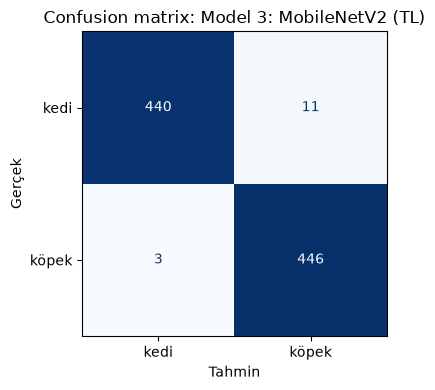

              precision    recall  f1-score   support

        kedi     0.9932    0.9756    0.9843       451
       köpek     0.9759    0.9933    0.9845       449

    accuracy                         0.9844       900
   macro avg     0.9846    0.9845    0.9844       900
weighted avg     0.9846    0.9844    0.9844       900



In [27]:
y_true = best["y_true"]
y_pred = (best["probs"] > 0.5).astype(int)
target_names = [CLASS_NAMES_TR[c] for c in CLASS_NAMES]

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm, display_labels=target_names).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion matrix: {best_name}")
ax.set_xlabel("Tahmin")
ax.set_ylabel("Gerçek")
plt.tight_layout()
plt.show()

print(classification_report(y_true, y_pred, target_names=target_names, digits=4))

### Yanlış sınıflanan görüntüler

Modelin en emin olduğu 9 hata. Görüntüler çizilmeden önce `denormalize` ile `x * std + mean` uygulanıp `[H, W, C]` sırasına çevriliyor.

Toplam yanlış: 14 / 900


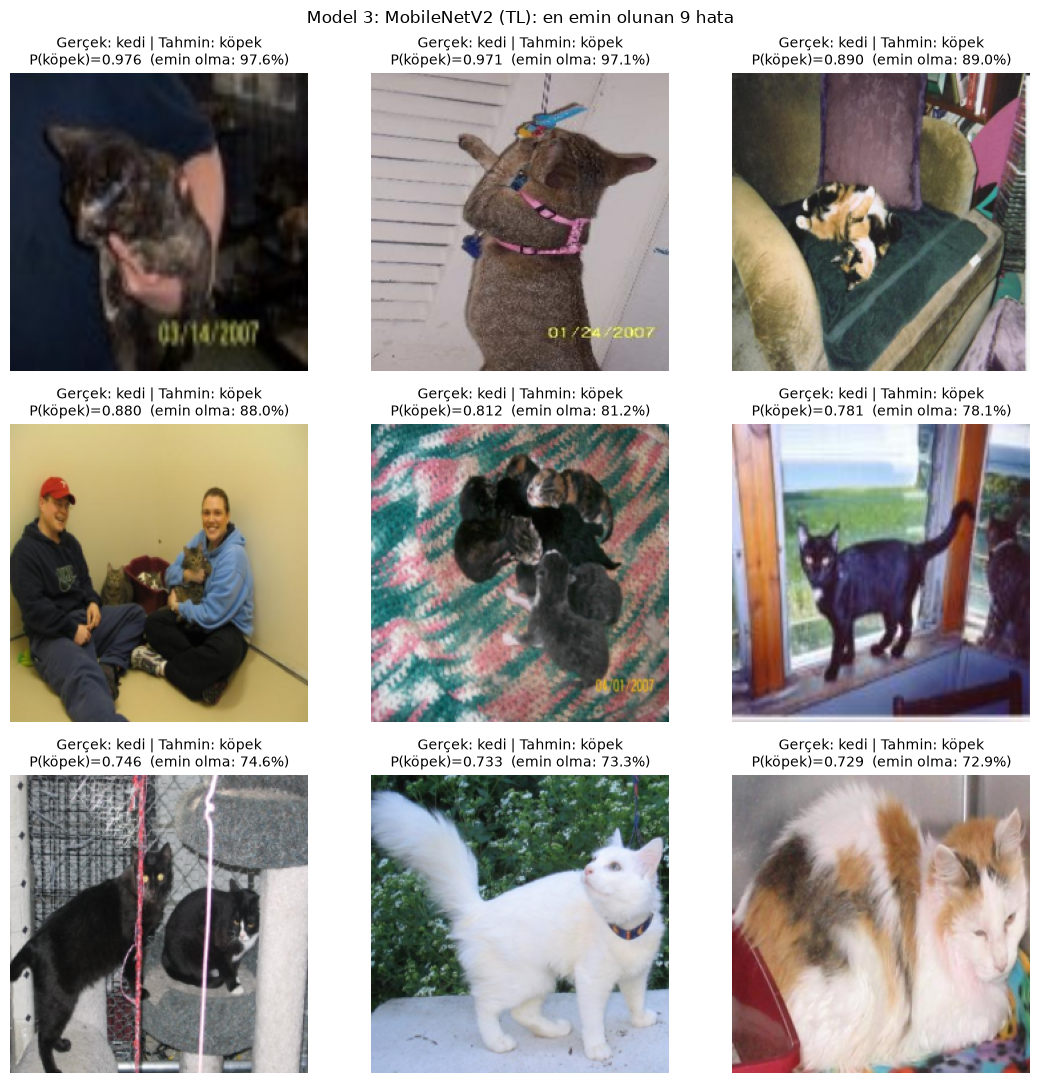

In [28]:
probs = best["probs"]
wrong_idx = np.where(y_pred != y_true)[0]
print(f"Toplam yanlış: {len(wrong_idx)} / {len(y_true)}")

# Tahmin edilen sınıfa ait olasılık: köpek dediyse p, kedi dediyse 1-p
pred_conf = np.where(y_pred == 1, probs, 1 - probs)
worst = wrong_idx[np.argsort(-pred_conf[wrong_idx])][:9]

fig, axes = plt.subplots(3, 3, figsize=(11, 11))
for ax, i in zip(axes.ravel(), worst):
    img_tensor, label = best["test_ds"][i]  # i. test örneği (shuffle=False olduğu için sıra aynı)
    ax.imshow(denormalize(img_tensor))
    ax.set_title(f"Gerçek: {target_names[label]} | Tahmin: {target_names[y_pred[i]]}\n"
                 f"P(köpek)={probs[i]:.3f}  (emin olma: {pred_conf[i]:.1%})", fontsize=10)
    ax.axis("off")
for ax in axes.ravel()[len(worst):]:
    ax.axis("off")
plt.suptitle(f"{best_name}: en emin olunan 9 hata")
plt.tight_layout()
plt.show()

**Model neden yanılmış olabilir?** Bunun yaygın nedenleri:
- Görüntü belirsiz ya da yanlış etiketlenmiş olabilir (iki hayvan birden, hayvan zor görünüyor).
- Kare boyuta sıkıştırma oranları bozar; küçük hayvanın yüzü birkaç piksele iner.
- Alışılmadık poz, kostüm, çizim, karanlık veya bulanık bir fotoğraf olabilir.
- Benzer görünen ırklar var (ör. küçük tüylü köpekler).
- Model hayvan yerine arka plana dayanıyor olabilir (*shortcut* öğrenme).

## 9. Tahmin fonksiyonu, kaydetme ve yükleme

- `predict_image(path)`: Görüntü eğitimdeki eval dönüşümünün aynısıyla işlenir; fonksiyon `("köpek", 0.98)` gibi bir sonuç döner.
- Model **`state_dict`** olarak kaydedilir; bu dosya yalnızca ağırlıkları içerir. Yüklerken aynı mimariden yeni bir nesne oluşturulup ağırlıklar ona yüklenir.
- Yüklenen model testte aynı sonucu vermeli. Bu yeni bir değerlendirme değil, sadece kaydetme ve yüklemenin doğru çalıştığının kontrolü.

In [29]:
# Model adı → (yeni boş model üreten fonksiyon, eval dönüşümü)
MODEL_FACTORY = {
    "Model 1: CNN": (lambda: SimpleCNN(dropout=0.0), eval_tf_cnn),
    "Model 2: CNN + aug + dropout": (lambda: SimpleCNN(dropout=DROPOUT_M2), eval_tf_cnn),
    # Ağırlıkları dosyadan yükleyeceğimiz için ImageNet ağırlıklarını tekrar indirmeye gerek yok
    "Model 3: MobileNetV2 (TL)": (lambda: build_mobilenet(pretrained=False), eval_tf_tl),
}

BEST_MODEL_PATH = MODELS_DIR / "best_model.pth"
torch.save(best["model"].state_dict(), BEST_MODEL_PATH)
print(f"Kaydedildi: {BEST_MODEL_PATH} ({BEST_MODEL_PATH.stat().st_size / 1e6:.1f} MB) | model: {best_name}")

# Yeni, sıfırdan bir model nesnesi oluştur ve kaydedilen ağırlıkları yükle
build_fn, best_eval_tf = MODEL_FACTORY[best_name]
loaded_model = build_fn()
loaded_model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device, weights_only=True))
loaded_model = loaded_model.to(device)
loaded_model.eval()  # tahmin için eval modu (Dropout kapalı, BatchNorm kayıtlı istatistikleri kullanır)

# Yüklenen modeli test setinde tekrar çalıştır: sonuç 8. bölümle aynı olmalı
_, reloaded_acc = evaluate(loaded_model, best["test_loader"], criterion, device)
reloaded_probs, _ = predict(loaded_model, best["test_loader"], device)
print(f"Orijinal model test accuracy : {best['test_acc']:.4f}")
print(f"Yüklenen model test accuracy : {reloaded_acc:.4f}")
print("Olasılıklar aynı mı?", np.allclose(reloaded_probs, best["probs"], atol=1e-5))

Kaydedildi: models/best_model.pth (9.1 MB) | model: Model 3: MobileNetV2 (TL)


Orijinal model test accuracy : 0.9844
Yüklenen model test accuracy : 0.9844
Olasılıklar aynı mı? True


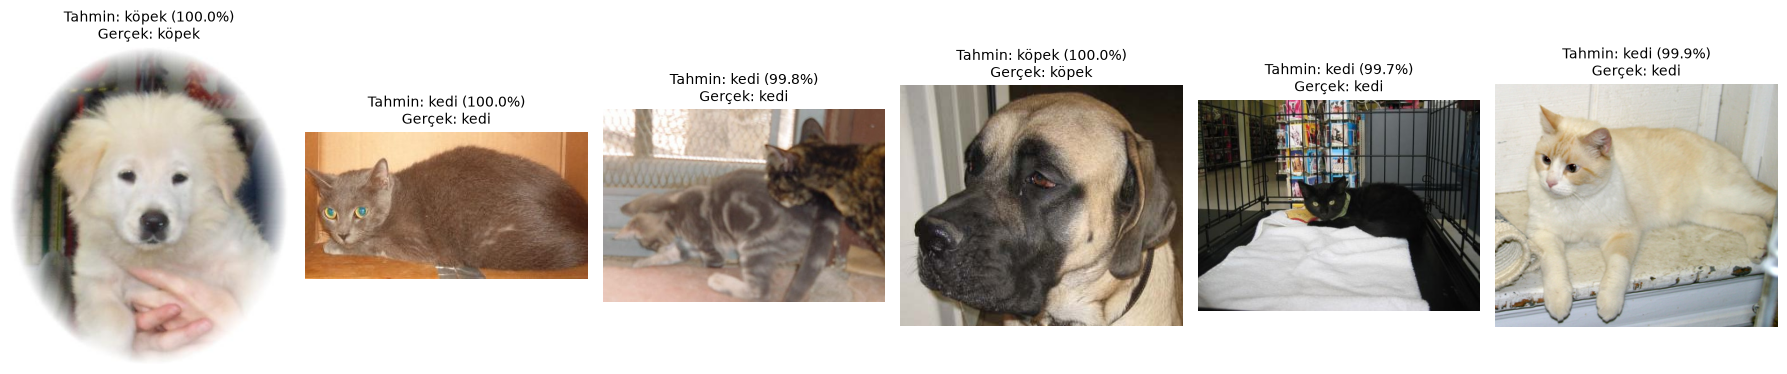

('köpek', 0.9999762773513794)


In [30]:
def predict_image(image_path, model: nn.Module = loaded_model, transform=best_eval_tf):
    # Tek bir görüntü için ("kedi" | "köpek", olasılık) döndürür
    with Image.open(image_path) as img:
        img = img.convert("RGB")               # gri/CMYK/RGBA görüntüleri de 3 kanala çevir
    x = transform(img).unsqueeze(0).to(device) # [C,H,W] → [1,C,H,W]: model her zaman batch bekler
    model.eval()
    with torch.no_grad():
        p_dog = torch.sigmoid(model(x)).item() # logit → köpek olma olasılığı
    if p_dog >= 0.5:
        return "köpek", p_dog
    return "kedi", 1 - p_dog                   # tahmin edilen sınıfın olasılığını döndürüyoruz


# Birkaç test görüntüsünde deneyelim
demo_rng = random.Random(SEED)
demo_samples = demo_rng.sample(best["test_ds"].samples, 6)

fig, axes = plt.subplots(1, 6, figsize=(18, 3.6))
for ax, (path, label) in zip(axes, demo_samples):
    pred_label, prob = predict_image(path)
    with Image.open(path) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(f"Tahmin: {pred_label} ({prob:.1%})\nGerçek: {target_names[label]}", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

print(predict_image(demo_samples[0][0]))

## 10. Sonuç

Aşağıdaki tablo sizin çalıştırmanızın sonuçlarını gösteriyor. Yorum, `SUBSET_SIZE = 6000` ile yerel GPU'da aldığımız sonuçlara dayanıyor:

| Model | Val acc | Test acc | Eğitilebilir parametre |
|---|---|---|---|
| Model 1: CNN | %86,9 | %84,1 | 389.153 |
| Model 2: CNN + aug + dropout | %86,2 | %87,2 | 389.153 |
| Model 3: MobileNetV2 (TL) | %99,0 | %98,4 | 1.207.361 |

In [31]:
summary = results[["Val accuracy", "Test accuracy", "Eğitilebilir parametre", "Eğitim süresi (sn)"]].copy()
summary["Epoch sayısı"] = [len(history1["train_loss"]), len(history2["train_loss"]), len(history3["train_loss"])]
display(summary.style.format({
    "Val accuracy": "{:.2%}", "Test accuracy": "{:.2%}",
    "Eğitilebilir parametre": "{:,}", "Eğitim süresi (sn)": "{:.0f}",
}))

,Val accuracy,Test accuracy,Eğitilebilir parametre,Eğitim süresi (sn),Epoch sayısı
Model,,,,,
Model 1: CNN,86.89%,84.11%,"389,153",116,30
Model 2: CNN + aug + dropout,86.22%,87.22%,"389,153",316,40
Model 3: MobileNetV2 (TL),99.00%,98.44%,"1,207,361",149,8


**Bulgular:** Veri temizliğinde içeriği JPEG olmayan 229 dosya ayıklandı. Sıfırdan CNN (Model 1) testte ~%84'e ulaştı, ancak açılan train/val farkı overfitting'e işaret ediyor. Augmentation ve dropout (Model 2), parametre sayısını değiştirmeden overfitting'i azalttı ve test başarısını ~%87'ye çıkardı; karşılığında eğitim daha uzun sürdü. Önceden eğitilmiş MobileNetV2 (Model 3) ise yalnızca sınıflandırıcı eğitilerek ilk epoch'ta %98'i geçti ve fine-tuning sonrası testte ~%98,4'e ulaştı. En büyük kazanç, büyük veride öğrenilmiş özellikleri yeniden kullanmaktan geldi. Kalan hatalar çoğunlukla belirsiz ya da yanlış etiketlenmiş görüntülerde. Tüm veriyle (`SUBSET_SIZE = None`), daha uzun eğitimle veya daha güçlü bir önceden eğitilmiş modelle sonuçlar daha da iyileşebilir.